In [57]:
from pathlib import Path
import json
import shutil
import warnings
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
from scipy.special import expit

try:
    from IPython.display import display
except ImportError:  # Allows the same file to run as a plain Python script.
    display = print

SEED = 2026
rng = np.random.default_rng(SEED)

# Locate the project root whether this runs from the root, the notebook folder,
# or the source-code folder.
def locate_project_root():
    candidates = [Path.cwd().resolve()]
    if "__file__" in globals():
        candidates.append(Path(__file__).resolve().parent)
        candidates.append(Path(__file__).resolve().parent.parent)
    for start in candidates:
        for candidate in [start, *start.parents]:
            if (candidate / "01_notebooks").is_dir() and (candidate / "02_source_code").is_dir():
                return candidate
    return Path.cwd().resolve()

PROJECT_ROOT = locate_project_root()
FIGURE_DIR = PROJECT_ROOT / "03_figures"
RESULT_DIR = PROJECT_ROOT / "04_results"
TABLE_DIR = RESULT_DIR / "tables"
PARAM_DIR = RESULT_DIR / "parameters"
DOC_DIR = PROJECT_ROOT / "05_documentation"

for folder in (FIGURE_DIR, TABLE_DIR, PARAM_DIR):
    if folder.exists():
        shutil.rmtree(folder)
    folder.mkdir(parents=True, exist_ok=True)
DOC_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (8.6, 5.4),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.family": "DejaVu Sans",
    "font.size": 10.5,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.grid": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 2.2,
    "legend.frameon": False,
    "savefig.bbox": "tight",
})


def save_figure(fig, filename):
    path = FIGURE_DIR / filename
    fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
    if "get_ipython" in globals():
        plt.show()
    plt.close(fig)
    return path

# Illustrative baseline parameter set. It is NOT a calibrated estimate for
# all MSM populations. Units are per year unless noted otherwise.
PARAMS = {
    "N0": 100_000.0, "mu": 0.005, "Lambda": 500.0,
    "du": 0.050, "dD": 0.020, "dT": 0.005, "dL": 0.030,
    "beta": None, "epsilon": 0.99,
    "etaD": 1.00, "etaT": 0.00, "etaL": 1.00,
    "nu0": 0.720, "omega0": 0.160, "tau0": 0.382,
    "kappa0": 2.660, "delta0": 0.034, "rho0": 0.500,
    "as": 0.300, "bs": 0.200, "xis": 0.200,
    "ac": 0.300, "bc": 0.200, "xic": 0.200,
    "zeta": 0.100, "us": 0.000, "uc": 0.000,
    "sigma_ref": 0.500, "C_ref": 0.500, "slope": 1.000,
}
TARGET_R0 = 1.20
T_END = 100.0
N_EVAL = 1001
RTOL, ATOL = 1e-8, 1e-10
STATE_NAMES = ["S", "P", "Iu", "D", "T", "L", "sigma", "C"]


def validate_parameters(p):
    assert np.isclose(p["Lambda"], p["mu"] * p["N0"], rtol=1e-12, atol=1e-12)
    assert p["mu"] > 0 and p["Lambda"] > 0 and p["N0"] > 0
    assert 0 <= p["epsilon"] <= 1
    assert p["slope"] > 0
    assert 0 <= p["sigma_ref"] <= 1 and 0 <= p["C_ref"] <= 1
    nonnegative = ["du", "dD", "dT", "dL", "nu0", "omega0", "tau0",
                   "kappa0", "delta0", "rho0", "as", "bs", "xis",
                   "ac", "bc", "xic", "zeta", "us", "uc",
                   "etaD", "etaT", "etaL"]
    for key in nonnegative:
        assert np.isfinite(p[key]) and p[key] >= 0, f"Invalid parameter: {key}"
    if p["beta"] is not None:
        assert np.isfinite(p["beta"]) and p["beta"] >= 0

validate_parameters(PARAMS)
print("Parameter-domain checks passed.")
print(f"Project directory: {PROJECT_ROOT}")

Parameter-domain checks passed.
Project directory: /drive/notebooks


In [58]:
def get_rates(sigma, confidence, p):
    """Socially modulated transition rates; each equals r0 at reference state."""
    z = p["slope"]

    def rate(r0, sign_sigma, sign_confidence):
        x = (sign_sigma * z * (sigma - p["sigma_ref"])
             + sign_confidence * z * (confidence - p["C_ref"]))
        return 2.0 * r0 * expit(x)

    return {
        "nu": rate(p["nu0"], -1, +1),
        "omega": rate(p["omega0"], +1, -1),
        "tau": rate(p["tau0"], -1, +1),
        "kappa": rate(p["kappa0"], -1, +1),
        "delta": rate(p["delta0"], +1, -1),
        "rho": rate(p["rho0"], -1, +1),
    }


def hiv_model(t, y, p):
    S, Pr, Iu, D, T, L, sigma, confidence = y
    N = S + Pr + Iu + D + T + L
    if N <= 0:
        raise ValueError("Total population must remain positive.")
    rates = get_rates(sigma, confidence, p)
    infectious_pressure = Iu + p["etaD"] * D + p["etaT"] * T + p["etaL"] * L
    lam = p["beta"] * infectious_pressure / N

    dS = p["Lambda"] - lam*S - rates["nu"]*S + rates["omega"]*Pr - p["mu"]*S
    dP = rates["nu"]*S - (1-p["epsilon"])*lam*Pr - (rates["omega"]+p["mu"])*Pr
    dIu = lam*S + (1-p["epsilon"])*lam*Pr - (rates["tau"]+p["mu"]+p["du"])*Iu
    dD = rates["tau"]*Iu - (rates["kappa"]+p["mu"]+p["dD"])*D
    dT = rates["kappa"]*D + rates["rho"]*L - (rates["delta"]+p["mu"]+p["dT"])*T
    dL = rates["delta"]*T - (rates["rho"]+p["mu"]+p["dL"])*L

    # h is the modeled rate of service engagement per capita.
    h = (rates["tau"]*Iu + rates["kappa"]*D) / N
    dsigma = (p["as"]*(1-sigma) - p["bs"]*sigma
              - p["xis"]*confidence*sigma - p["us"]*sigma)
    dconfidence = ((p["ac"]+p["uc"])*(1-confidence) - p["bc"]*confidence
                   - p["xic"]*sigma*confidence
                   + p["zeta"]*h*(1-confidence))
    return np.array([dS, dP, dIu, dD, dT, dL, dsigma, dconfidence], dtype=float)


def calculate_dfe(p):
    """Disease-free equilibrium, solving the two-dimensional social subsystem."""
    def social_rhs(z):
        sigma, confidence = z
        return np.array([
            p["as"]*(1-sigma) - p["bs"]*sigma - p["xis"]*confidence*sigma - p["us"]*sigma,
            (p["ac"]+p["uc"])*(1-confidence) - p["bc"]*confidence
            - p["xic"]*sigma*confidence,
        ])

    sol = least_squares(social_rhs, x0=np.array([p["sigma_ref"], p["C_ref"]]),
                        bounds=(np.zeros(2), np.ones(2)),
                        xtol=1e-14, ftol=1e-14, gtol=1e-14, max_nfev=5000)
    social_residual = np.max(np.abs(social_rhs(sol.x)))
    if (not sol.success) or social_residual > 1e-10:
        raise RuntimeError(f"Social DFE solve failed; residual={social_residual:.3e}")
    sigma0, confidence0 = sol.x
    rates = get_rates(sigma0, confidence0, p)
    N0 = p["Lambda"] / p["mu"]
    denominator = rates["nu"] + rates["omega"] + p["mu"]
    S0 = N0 * (rates["omega"] + p["mu"]) / denominator
    P0 = N0 * rates["nu"] / denominator
    return np.array([S0, P0, 0.0, 0.0, 0.0, 0.0, sigma0, confidence0])


def calculate_R0_analytic(p):
    """Closed-form R0 from the infected transition subsystem."""
    dfe = calculate_dfe(p)
    rates = get_rates(dfe[6], dfe[7], p)
    a = rates["tau"] + p["mu"] + p["du"]
    b = rates["kappa"] + p["mu"] + p["dD"]
    c = rates["delta"] + p["mu"] + p["dT"]
    d = rates["rho"] + p["mu"] + p["dL"]
    Delta = c*d - rates["rho"]*rates["delta"]
    if min(a, b, Delta) <= 0:
        raise ValueError("Infected transition subsystem is not invertible.")
    Ndf = dfe[0] + dfe[1]
    m0 = p["beta"] * (dfe[0] + (1-p["epsilon"])*dfe[1]) / Ndf
    return (m0/a) * (1 + p["etaD"]*rates["tau"]/b
        + rates["kappa"]*rates["tau"]*(p["etaT"]*d+p["etaL"]*rates["delta"])/(b*Delta))


def calculate_R0_ngm(p):
    """Independent next-generation-matrix spectral-radius check."""
    dfe = calculate_dfe(p)
    rates = get_rates(dfe[6], dfe[7], p)
    a = rates["tau"] + p["mu"] + p["du"]
    b = rates["kappa"] + p["mu"] + p["dD"]
    c = rates["delta"] + p["mu"] + p["dT"]
    d = rates["rho"] + p["mu"] + p["dL"]
    V = np.array([
        [a, 0.0, 0.0, 0.0],
        [-rates["tau"], b, 0.0, 0.0],
        [0.0, -rates["kappa"], c, -rates["rho"]],
        [0.0, 0.0, -rates["delta"], d],
    ])
    Ndf = dfe[0] + dfe[1]
    m0 = p["beta"] * (dfe[0] + (1-p["epsilon"])*dfe[1]) / Ndf
    F = np.zeros((4, 4))
    F[0, :] = m0 * np.array([1.0, p["etaD"], p["etaT"], p["etaL"]])
    K = F @ np.linalg.solve(V, np.eye(4))
    return float(np.max(np.abs(np.linalg.eigvals(K))))

# Calibrate beta only to a stated illustrative target; this is a scenario choice.
PARAMS["beta"] = 1.0
PARAMS["beta"] = TARGET_R0 / calculate_R0_analytic(PARAMS)
DFE = calculate_dfe(PARAMS)
R0_BASE = calculate_R0_analytic(PARAMS)
R0_NGM = calculate_R0_ngm(PARAMS)
DFE_RHS = hiv_model(0.0, DFE, PARAMS)

assert np.isclose(R0_BASE, TARGET_R0, rtol=1e-10, atol=1e-10)
assert np.isclose(R0_BASE, R0_NGM, rtol=1e-9, atol=1e-10)
assert np.max(np.abs(DFE_RHS)) < 1e-8
assert np.all(DFE[:6] >= 0) and 0 <= DFE[6] <= 1 and 0 <= DFE[7] <= 1

print("DFE:", dict(zip(STATE_NAMES, DFE)))
print(f"beta = {PARAMS['beta']:.10g} per year")
print(f"R0 analytic = {R0_BASE:.10f}; R0 from NGM = {R0_NGM:.10f}")
print(f"Maximum absolute DFE residual = {np.max(np.abs(DFE_RHS)):.3e}")

DFE: {'S': np.float64(18644.06779661017), 'P': np.float64(81355.93220338984), 'Iu': np.float64(0.0), 'D': np.float64(0.0), 'T': np.float64(0.0), 'L': np.float64(0.0), 'sigma': np.float64(0.5), 'C': np.float64(0.5)}
beta = 0.8666673035 per year
R0 analytic = 1.2000000000; R0 from NGM = 1.2000000000
Maximum absolute DFE residual = 2.970e-12


,Check,Value,Unit
0,ODE solver success,True,Boolean
1,Minimum population compartment,0.0,individuals
2,Minimum social state,0.5,index
3,Maximum social state,0.5,index
4,Population-balance identity max error,0.0,individuals/year
5,Initial HIV prevalence,0.001,%
6,HIV prevalence at 100 years (transient),0.002125,%
7,Total population at 100 years,99998.744171,individuals


<ipython-input-57-b08d2acb2813>:67: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
<ipython-input-57-b08d2acb2813>:67: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")


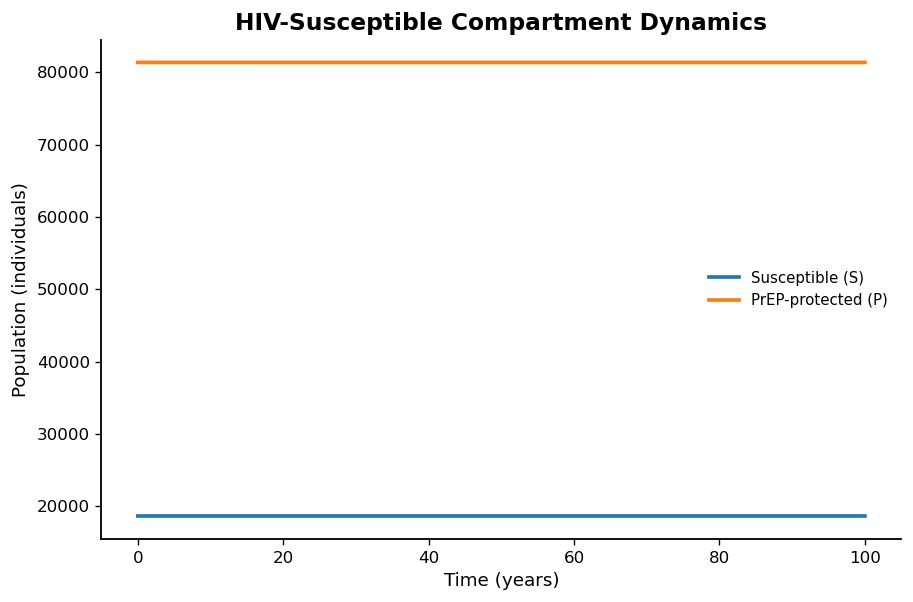

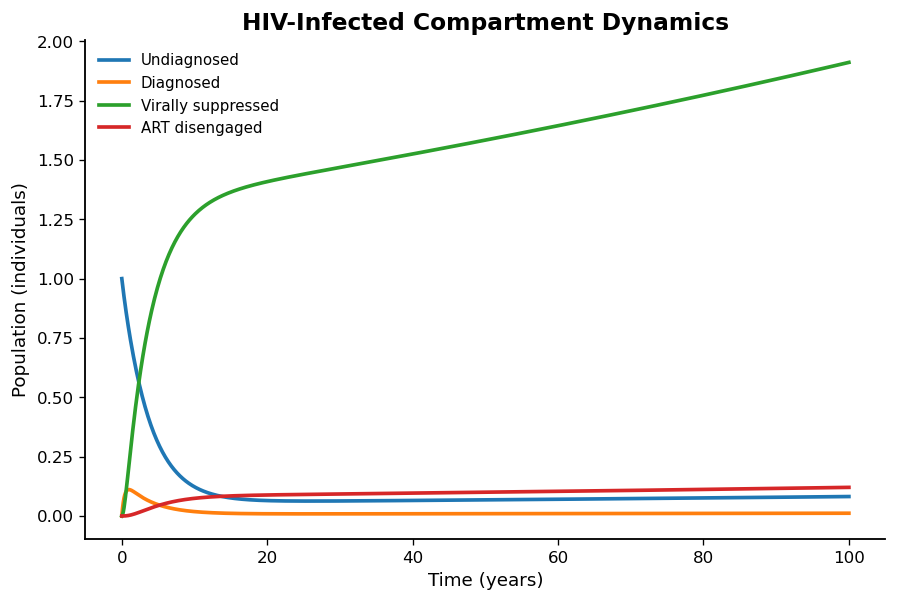

<ipython-input-57-b08d2acb2813>:67: MatplotlibDeprecationWarning: The width parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(width) instead.
  fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
<ipython-input-57-b08d2acb2813>:67: MatplotlibDeprecationWarning: The height parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(height) instead.
  fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")


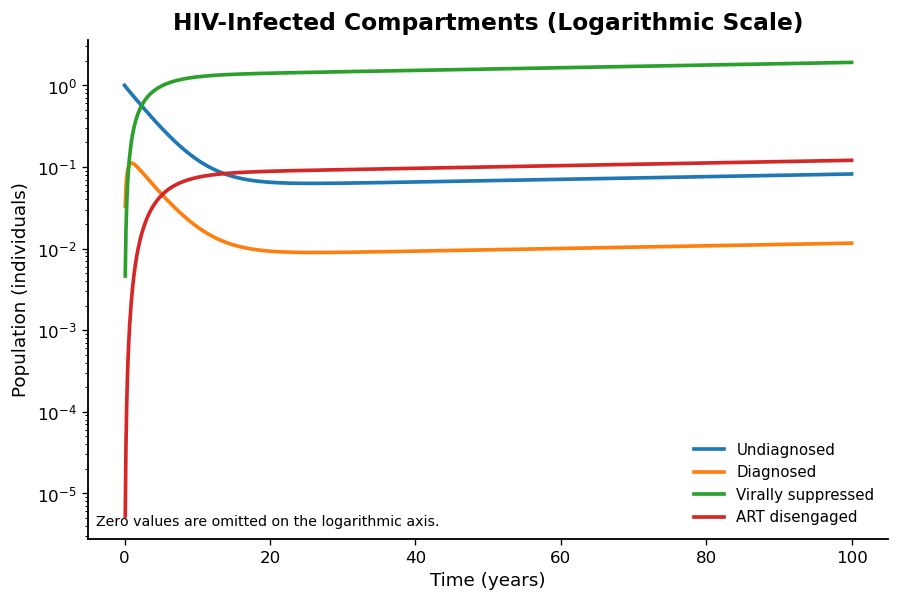

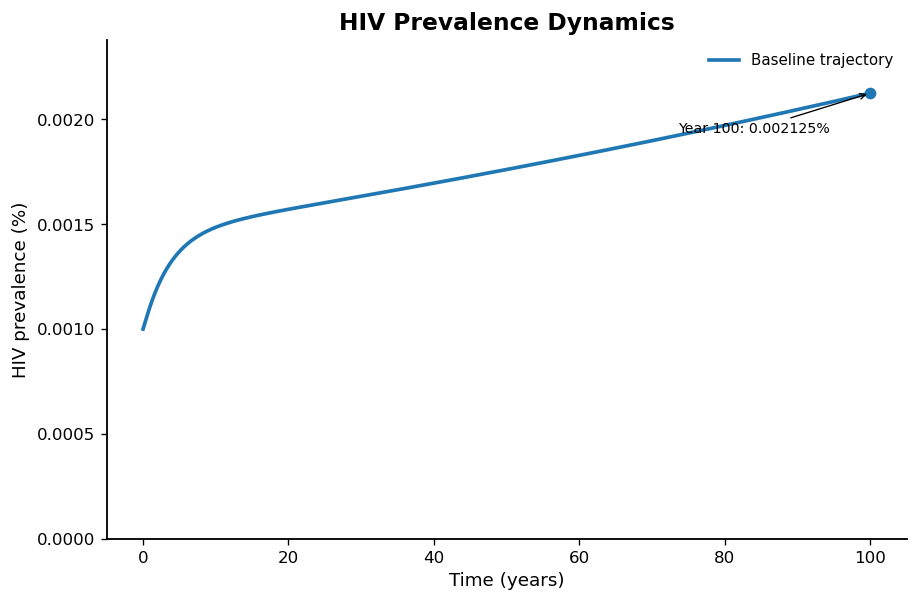

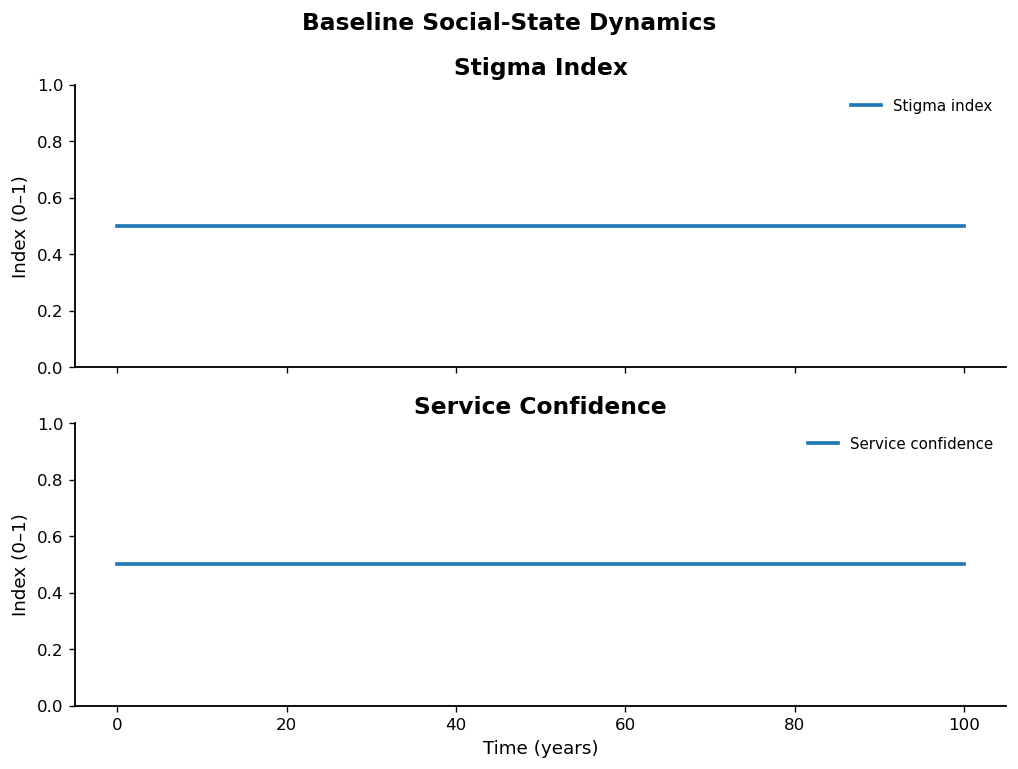

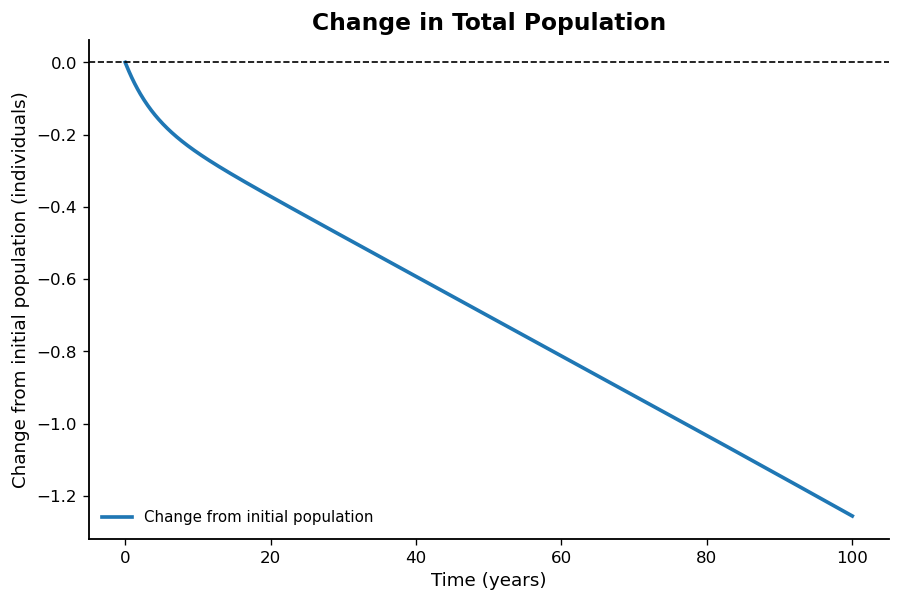

Baseline ODE integration and population-balance check completed.


In [59]:
def simulate(p, y0, end_time=T_END, n_points=N_EVAL):
    t_eval = np.linspace(0.0, end_time, n_points)
    sol = solve_ivp(lambda t, y: hiv_model(t, y, p), (0.0, end_time),
                    np.asarray(y0, dtype=float), method="BDF", t_eval=t_eval,
                    rtol=RTOL, atol=ATOL)
    if not sol.success:
        raise RuntimeError(f"ODE integration failed: {sol.message}")
    pop = sol.y[:6]
    social = sol.y[6:8]
    if np.min(pop) < -1e-7:
        raise RuntimeError(f"Negative population compartment: {np.min(pop):.3e}")
    if np.min(social) < -1e-8 or np.max(social) > 1.0+1e-8:
        raise RuntimeError("Social state left the admissible interval [0,1].")
    return sol

# One initial diagnosed-status seed: move one person from S to undiagnosed Iu.
Y0 = DFE.copy()
Y0[0] -= 1.0
Y0[2] = 1.0
if Y0[0] < 0:
    raise ValueError("Initial susceptible population cannot be negative.")

baseline_sol = simulate(PARAMS, Y0)
Y = baseline_sol.y
N = Y[:6].sum(axis=0)
INFECTED = Y[2:6].sum(axis=0)
PREV_PCT = 100.0 * INFECTED / N

# The exact total-population equation implied by the six population ODEs.
rhs_population_sum = np.array([
    hiv_model(t, Y[:, i], PARAMS)[:6].sum()
    for i, t in enumerate(baseline_sol.t)
])
expected_population_rhs = (PARAMS["Lambda"] - PARAMS["mu"]*N
    - PARAMS["du"]*Y[2] - PARAMS["dD"]*Y[3]
    - PARAMS["dT"]*Y[4] - PARAMS["dL"]*Y[5])
population_identity_error = float(np.max(np.abs(rhs_population_sum-expected_population_rhs)))

baseline_diagnostics = pd.DataFrame([
    ["ODE solver success", bool(baseline_sol.success), "Boolean"],
    ["Minimum population compartment", float(np.min(Y[:6])), "individuals"],
    ["Minimum social state", float(np.min(Y[6:8])), "index"],
    ["Maximum social state", float(np.max(Y[6:8])), "index"],
    ["Population-balance identity max error", population_identity_error, "individuals/year"],
    ["Initial HIV prevalence", float(PREV_PCT[0]), "%"],
    ["HIV prevalence at 100 years (transient)", float(PREV_PCT[-1]), "%"],
    ["Total population at 100 years", float(N[-1]), "individuals"],
], columns=["Check", "Value", "Unit"])
display(baseline_diagnostics)
baseline_diagnostics.to_csv(TABLE_DIR/"baseline_diagnostics.csv", index=False)

# Figure 01 — susceptible compartments.
fig, ax = plt.subplots()
ax.plot(baseline_sol.t, Y[0], label="Susceptible (S)")
ax.plot(baseline_sol.t, Y[1], label="PrEP-protected (P)")
ax.set(title="HIV-Susceptible Compartment Dynamics",
       xlabel="Time (years)", ylabel="Population (individuals)")
ax.legend(loc="best")
save_figure(fig, "figure_01_susceptible.png")

# Figure 02 — infected compartments, linear scale.
fig, ax = plt.subplots()
for idx, label in zip([2, 3, 4, 5],
                      ["Undiagnosed", "Diagnosed", "Virally suppressed", "ART disengaged"]):
    ax.plot(baseline_sol.t, Y[idx], label=label)
ax.set(title="HIV-Infected Compartment Dynamics",
       xlabel="Time (years)", ylabel="Population (individuals)")
ax.legend(loc="best")
save_figure(fig, "figure_02_infected.png")

# Figure 03 — logarithmic view; exact zero values are masked, not fabricated.
fig, ax = plt.subplots()
for idx, label in zip([2, 3, 4, 5],
                      ["Undiagnosed", "Diagnosed", "Virally suppressed", "ART disengaged"]):
    values = np.where(Y[idx] > 0, Y[idx], np.nan)
    ax.plot(baseline_sol.t, values, label=label)
ax.set_yscale("log")
ax.set(title="HIV-Infected Compartments (Logarithmic Scale)",
       xlabel="Time (years)", ylabel="Population (individuals)")
ax.legend(loc="best")
ax.text(0.01, 0.02, "Zero values are omitted on the logarithmic axis.",
        transform=ax.transAxes, fontsize=8.5, va="bottom")
save_figure(fig, "figure_03_infected_log.png")

# Figure 04 — prevalence plotted from zero to avoid a misleading truncated axis.
fig, ax = plt.subplots()
ax.plot(baseline_sol.t, PREV_PCT, label="Baseline trajectory")
ax.scatter([baseline_sol.t[-1]], [PREV_PCT[-1]], zorder=3)
ax.set_ylim(bottom=0, top=max(PREV_PCT.max()*1.12, 1e-8))
ax.set(title="HIV Prevalence Dynamics",
       xlabel="Time (years)", ylabel="HIV prevalence (%)")
ax.annotate(f"Year 100: {PREV_PCT[-1]:.6f}%",
            xy=(baseline_sol.t[-1], PREV_PCT[-1]),
            xytext=(-115, -24), textcoords="offset points", fontsize=8.5,
            arrowprops={"arrowstyle": "->", "lw": 0.8})
ax.legend(loc="best")
save_figure(fig, "figure_04_prevalence.png")

# Figure 05 — separate panels make both social states readable without
# hiding one curve behind the other when trajectories overlap.
fig, axes = plt.subplots(2, 1, figsize=(8.6, 6.5), sharex=True)
axes[0].plot(baseline_sol.t, Y[6], label="Stigma index")
axes[0].set(title="Stigma Index", ylabel="Index (0–1)", ylim=(0, 1))
axes[0].legend(loc="best")
axes[1].plot(baseline_sol.t, Y[7], label="Service confidence")
axes[1].set(title="Service Confidence", xlabel="Time (years)",
            ylabel="Index (0–1)", ylim=(0, 1))
axes[1].legend(loc="best")
fig.suptitle("Baseline Social-State Dynamics", fontsize=14, fontweight="bold")
fig.tight_layout()
save_figure(fig, "figure_05_social.png")

# Figure 06 — plot the change from initial population rather than a tiny,
# visually exaggerated slice of the absolute population scale.
fig, ax = plt.subplots()
population_change = N - N[0]
ax.plot(baseline_sol.t, population_change, label="Change from initial population")
ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set(title="Change in Total Population",
       xlabel="Time (years)", ylabel="Change from initial population (individuals)")
ax.legend(loc="best")
save_figure(fig, "figure_06_population_change.png")

baseline_trajectory = pd.DataFrame({
    "time_years": baseline_sol.t,
    **{STATE_NAMES[i]: Y[i] for i in range(8)},
    "total_population": N,
    "HIV_prevalence_percent": PREV_PCT,
})
baseline_trajectory.to_csv(TABLE_DIR/"baseline_time_series.csv", index=False)
pd.DataFrame({"State": STATE_NAMES, "DFE_value": DFE}).to_csv(
    TABLE_DIR/"disease_free_equilibrium.csv", index=False)

print("Baseline ODE integration and population-balance check completed.")

In [60]:
# Scale population states by N0. A nonsingular diagonal scaling preserves
# Jacobian eigenvalues (the Jacobians are related by a similarity transform).
def to_scaled(y, p):
    z = np.asarray(y, dtype=float).copy()
    z[:6] /= p["N0"]
    return z


def from_scaled(z, p):
    y = np.asarray(z, dtype=float).copy()
    y[:6] *= p["N0"]
    return y


def scaled_rhs(z, p):
    y = from_scaled(z, p)
    f = hiv_model(0.0, y, p)
    return np.r_[f[:6]/p["N0"], f[6:]]


def jacobian_scaled(z, p, step=1e-6):
    z = np.asarray(z, dtype=float)
    J = np.zeros((8, 8))
    for j in range(8):
        h = step * max(1.0, abs(z[j]))
        zp, zm = z.copy(), z.copy()
        zp[j] += h
        zm[j] -= h
        J[:, j] = (scaled_rhs(zp, p)-scaled_rhs(zm, p))/(2*h)
    return J


def equilibrium_residual_table(y, p):
    residual = hiv_model(0.0, y, p)
    return pd.DataFrame({"Equation": STATE_NAMES,
                         "Absolute_residual": np.abs(residual)})


def find_equilibria(p, extra_starts=None, tol=1e-9):
    dfe = calculate_dfe(p)
    seeds = [
        [0.80, 0.15, 0.020, 0.005, 0.020, 0.005],
        [0.60, 0.25, 0.050, 0.020, 0.050, 0.020],
        [0.40, 0.30, 0.100, 0.050, 0.100, 0.050],
        [0.90, 0.05, 0.001, 0.001, 0.020, 0.001],
        [0.20, 0.20, 0.200, 0.100, 0.200, 0.100],
    ]
    starts = [np.r_[np.asarray(s, dtype=float)*p["N0"], dfe[6], dfe[7]]
              for s in seeds]
    if extra_starts:
        starts.extend(extra_starts)

    lower = np.zeros(8)
    # For equilibria, total population cannot exceed Lambda/mu when all
    # additional mortality rates are nonnegative. A conservative 1.05*N0
    # componentwise upper bound allows numerical slack.
    upper = np.r_[np.full(6, 1.05), 1.0, 1.0]
    found = [dfe.copy()]  # DFE is included analytically, not numerically rediscovered.
    fit_records = []

    for y0 in starts:
        z0 = np.clip(to_scaled(y0, p), lower+1e-12, upper-1e-12)
        fit = least_squares(lambda z: scaled_rhs(z, p), z0,
                            bounds=(lower, upper), x_scale="jac",
                            ftol=1e-13, xtol=1e-13, gtol=1e-13,
                            max_nfev=30000)
        y = from_scaled(fit.x, p)
        f = hiv_model(0.0, y, p)
        rel_pop_res = float(np.max(np.abs(f[:6])) / max(p["Lambda"], 1.0))
        social_res = float(np.max(np.abs(f[6:])))
        feasible = (np.min(y[:6]) >= -1e-7 and
                    -1e-8 <= y[6] <= 1+1e-8 and
                    -1e-8 <= y[7] <= 1+1e-8)
        accepted = (rel_pop_res < tol and social_res < tol and feasible)
        fit_records.append({"optimizer_success": bool(fit.success),
                            "relative_population_residual": rel_pop_res,
                            "social_residual": social_res,
                            "feasible": bool(feasible),
                            "accepted": bool(accepted)})
        if accepted:
            if not any(np.linalg.norm(to_scaled(y, p)-to_scaled(old, p)) < 1e-6
                       for old in found):
                found.append(y)

    return found, fit_records


def stability_eigenvalues(y, p):
    return np.linalg.eigvals(jacobian_scaled(to_scaled(y, p), p))


equilibria, equilibrium_fit_log = find_equilibria(PARAMS)
eq_rows = []
for index, state in enumerate(equilibria, start=1):
    eigenvalues = stability_eigenvalues(state, PARAMS)
    max_real = float(np.max(eigenvalues.real))
    infected_at_eq = float(np.sum(state[2:6]))
    prevalence_eq = 100.0 * infected_at_eq / np.sum(state[:6])
    state_residual = hiv_model(0.0, state, PARAMS)
    eq_rows.append({
        "Candidate": index,
        "Type": "DFE" if infected_at_eq < 1e-6 else "Endemic",
        "Prevalence_percent": prevalence_eq,
        "Max_absolute_ODE_residual": float(np.max(np.abs(state_residual))),
        "Relative_population_residual": float(np.max(np.abs(state_residual[:6])) / PARAMS["Lambda"]),
        "Max_absolute_social_residual": float(np.max(np.abs(state_residual[6:]))),
        "Max_real_eigenvalue_per_year": max_real,
        "Local_stability": "Stable" if max_real < -1e-7 else ("Unstable" if max_real > 1e-7 else "Inconclusive_near_zero"),
    })
    equilibrium_residual_table(state, PARAMS).to_csv(
        TABLE_DIR/f"equilibrium_{index}_residuals.csv", index=False)

equilibrium_table = pd.DataFrame(eq_rows)
display(equilibrium_table)
equilibrium_table.to_csv(TABLE_DIR/"verified_equilibrium_candidates.csv", index=False)
pd.DataFrame(equilibrium_fit_log).to_csv(TABLE_DIR/"equilibrium_solver_audit.csv", index=False)

if not any(row["Type"] == "Endemic" for row in eq_rows):
    raise RuntimeError("No endemic equilibrium candidate passed residual and feasibility checks.")

DFE_EIG = stability_eigenvalues(DFE, PARAMS)
DFE_MAX_REAL = float(np.max(DFE_EIG.real))
print(f"DFE maximum real eigenvalue = {DFE_MAX_REAL:.8e} per year")
print("Positive maximum real part indicates local instability of the DFE.")

,Candidate,Type,Prevalence_percent,Max_absolute_ODE_residual,Relative_population_residual,Max_absolute_social_residual,Max_real_eigenvalue_per_year,Local_stability
0,1,DFE,0.000000,2.970069e-12,5.940137e-15,1.387779e-17,0.00376,Unstable
1,2,Endemic,16.675335,1.312453e-07,2.624907e-10,1.764927e-14,-0.00427,Stable


DFE maximum real eigenvalue = 3.75980451e-03 per year
Positive maximum real part indicates local instability of the DFE.


<ipython-input-57-b08d2acb2813>:67: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
<ipython-input-57-b08d2acb2813>:67: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")


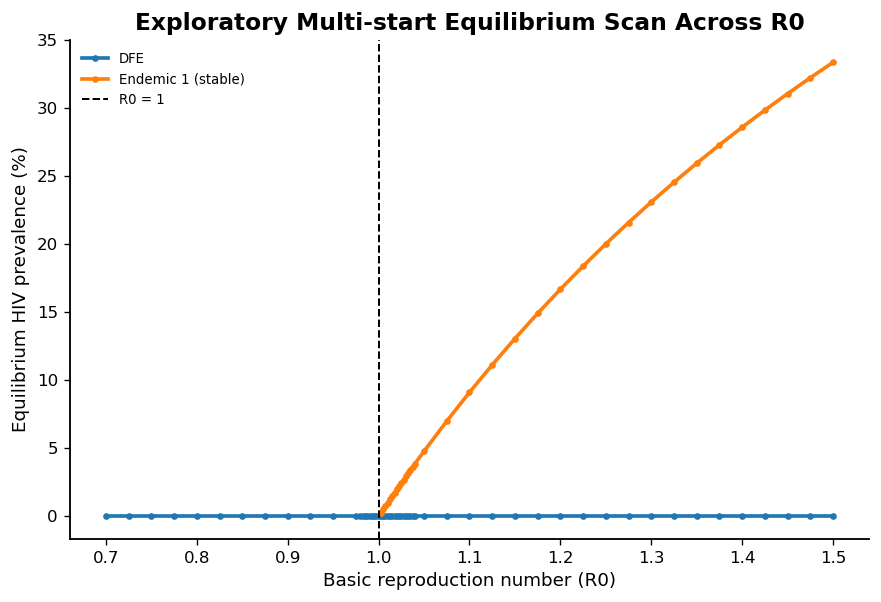

Equilibrium scan completed. It is exploratory multi-start root finding, not pseudo-arclength continuation.


In [61]:
# The grid is denser close to R0=1, where a threshold-related branch may emerge.
R0_GRID = np.unique(np.r_[np.linspace(0.70, 1.50, 33),
                          np.linspace(0.98, 1.04, 25)])
branch_rows = []
previous_endemic = []

for target_r0 in R0_GRID:
    p = PARAMS.copy()
    p["beta"] = PARAMS["beta"] * target_r0 / R0_BASE
    actual_r0 = calculate_R0_analytic(p)
    dfe = calculate_dfe(p)
    candidates, _ = find_equilibria(p, extra_starts=previous_endemic)

    dfe_eig = stability_eigenvalues(dfe, p)
    branch_rows.append({
        "R0": actual_r0, "Branch": "DFE", "Prevalence_percent": 0.0,
        "Max_absolute_residual": float(np.max(np.abs(hiv_model(0.0, dfe, p)))),
        "Max_real_eigenvalue_per_year": float(np.max(dfe_eig.real)),
    })

    endemic_now = [state for state in candidates if np.sum(state[2:6]) > 1e-5]
    for branch_index, state in enumerate(endemic_now, start=1):
        eig = stability_eigenvalues(state, p)
        branch_residual = hiv_model(0.0, state, p)
        branch_rows.append({
            "R0": actual_r0, "Branch": f"Endemic {branch_index}",
            "Prevalence_percent": 100.0*np.sum(state[2:6])/np.sum(state[:6]),
            "Max_absolute_residual": float(np.max(np.abs(branch_residual))),
            "Relative_population_residual": float(np.max(np.abs(branch_residual[:6])) / p["Lambda"]),
            "Max_absolute_social_residual": float(np.max(np.abs(branch_residual[6:]))),
            "Max_real_eigenvalue_per_year": float(np.max(eig.real)),
        })
    previous_endemic = endemic_now

branch_table = pd.DataFrame(branch_rows)
branch_table.to_csv(TABLE_DIR/"exploratory_equilibrium_branch_scan.csv", index=False)

fig, ax = plt.subplots()
dfe_group = branch_table[branch_table["Branch"] == "DFE"]
ax.plot(dfe_group["R0"], dfe_group["Prevalence_percent"],
        marker="o", markersize=3, label="DFE")
for branch_name, group in branch_table[branch_table["Branch"] != "DFE"].groupby("Branch"):
    stable = group[group["Max_real_eigenvalue_per_year"] < -1e-7]
    unstable = group[group["Max_real_eigenvalue_per_year"] > 1e-7]
    near = group[(group["Max_real_eigenvalue_per_year"] >= -1e-7) &
                 (group["Max_real_eigenvalue_per_year"] <= 1e-7)]
    if not stable.empty:
        ax.plot(stable["R0"], stable["Prevalence_percent"], marker="o",
                markersize=3, linestyle="-", label=f"{branch_name} (stable)")
    if not unstable.empty:
        ax.plot(unstable["R0"], unstable["Prevalence_percent"], marker="x",
                markersize=5, linestyle="--", label=f"{branch_name} (unstable)")
    if not near.empty:
        ax.plot(near["R0"], near["Prevalence_percent"], marker="s",
                markersize=4, linestyle="none", label=f"{branch_name} (near-zero eigenvalue)")
ax.axvline(1.0, color="black", linestyle="--", linewidth=1.2, label="R0 = 1")
ax.set(title="Exploratory Multi-start Equilibrium Scan Across R0",
       xlabel="Basic reproduction number (R0)",
       ylabel="Equilibrium HIV prevalence (%)")
ax.legend(loc="best", fontsize=8)
save_figure(fig, "figure_07_exploratory_equilibrium_scan.png")

print("Equilibrium scan completed. It is exploratory multi-start root finding, not pseudo-arclength continuation.")

,Parameter,Elasticity
0,epsilon,-4.139373
1,nu0,-0.771747
6,rho0,-0.483697
3,tau0,-0.195715
4,kappa0,-0.039434
7,slope,0.000000
5,delta0,0.517556
2,omega0,0.748361


<ipython-input-57-b08d2acb2813>:67: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
<ipython-input-57-b08d2acb2813>:67: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")


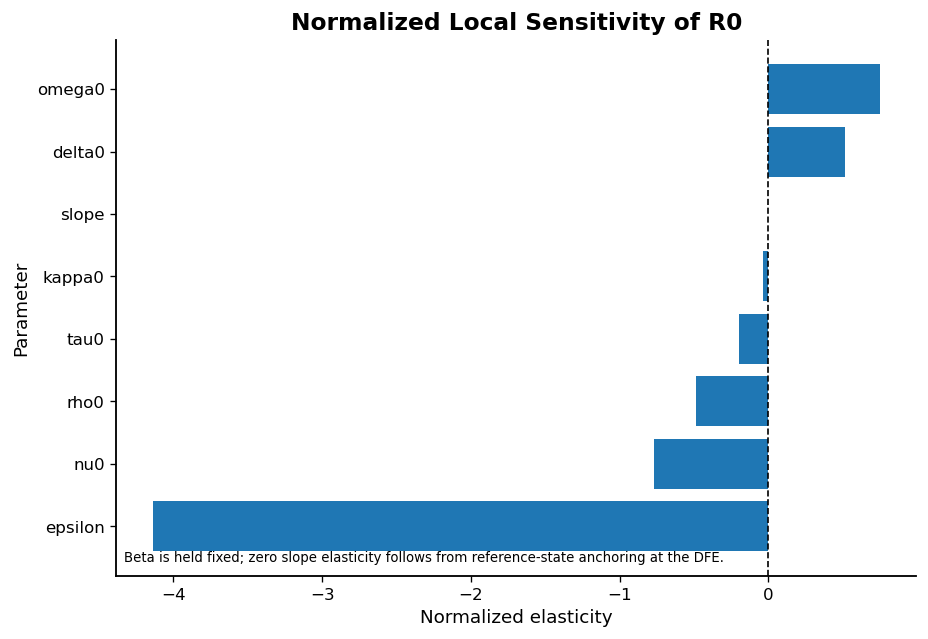

,R0
count,500.000000
mean,2.201237
std,0.881012
min,0.574442
2.5%,0.887979
50%,2.019743
97.5%,4.244059
max,5.246565
fraction_R0_above_1,0.956000


<ipython-input-57-b08d2acb2813>:67: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
<ipython-input-57-b08d2acb2813>:67: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")


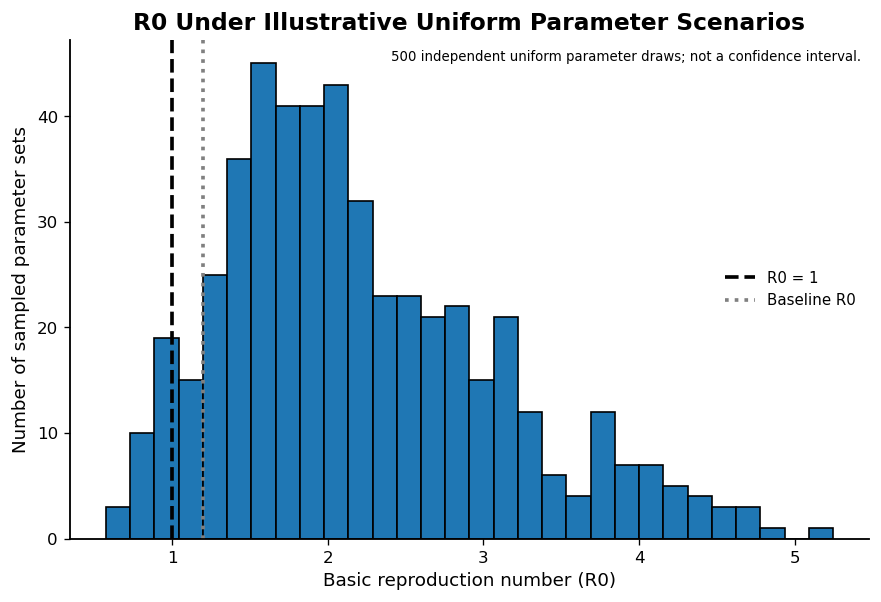

PosixPath('/drive/notebooks/03_figures/figure_09_R0_uncertainty.png')

In [62]:
# One-at-a-time values are evaluated with beta fixed at its baseline calibration.
SENSITIVITY_RANGES = {
    "epsilon": [0.80, 0.90, 0.99],
    "nu0": [0.30, 0.72, 1.00],
    "omega0": [0.08, 0.16, 0.35],
    "tau0": [0.30, 0.382, 0.52],
    "kappa0": [1.86, 2.66, 4.02],
    "delta0": [0.017, 0.034, 0.060],
    "rho0": [0.20, 0.50, 1.00],
    "slope": [0.50, 1.00, 2.00],
}
oat_records = []
for name, values in SENSITIVITY_RANGES.items():
    for value in values:
        p = PARAMS.copy()
        p[name] = value
        oat_records.append({"Parameter": name, "Value": value,
                            "R0_with_beta_fixed": calculate_R0_analytic(p)})
oat_table = pd.DataFrame(oat_records)
oat_table.to_csv(TABLE_DIR/"one_at_a_time_R0_sensitivity.csv", index=False)

local_records = []
for name in SENSITIVITY_RANGES:
    q = PARAMS[name]
    step = max(abs(q)*1e-5, 1e-7)
    p_plus, p_minus = PARAMS.copy(), PARAMS.copy()
    p_plus[name] = q + step
    p_minus[name] = max(q-step, 1e-10)
    derivative = ((calculate_R0_analytic(p_plus)-calculate_R0_analytic(p_minus))
                  / (p_plus[name]-p_minus[name]))
    elasticity = q/R0_BASE * derivative
    local_records.append({"Parameter": name, "Elasticity": elasticity})
local_sensitivity = pd.DataFrame(local_records).sort_values("Elasticity")
local_sensitivity.to_csv(TABLE_DIR/"local_R0_elasticity.csv", index=False)
display(local_sensitivity)

fig, ax = plt.subplots(figsize=(8.6, 5.8))
ax.barh(local_sensitivity["Parameter"], local_sensitivity["Elasticity"])
ax.axvline(0.0, color="black", linestyle="--", linewidth=1)
ax.set(title="Normalized Local Sensitivity of R0",
       xlabel="Normalized elasticity", ylabel="Parameter")
ax.text(0.01, 0.02,
        "Beta is held fixed; zero slope elasticity follows from reference-state anchoring at the DFE.",
        transform=ax.transAxes, fontsize=8, va="bottom")
save_figure(fig, "figure_08_R0_sensitivity.png")

# Independent uniform scenario sampling; NOT a posterior or empirical CI.
UNCERTAINTY_RANGES = {
    "epsilon": (0.80, 0.99), "nu0": (0.30, 1.00),
    "omega0": (0.08, 0.35), "tau0": (0.30, 0.52),
    "kappa0": (1.86, 4.02), "delta0": (0.017, 0.060),
    "rho0": (0.20, 1.00), "slope": (0.50, 2.00),
}
N_SAMPLES = 500
sample_records = []
for sample_id in range(1, N_SAMPLES+1):
    p = PARAMS.copy()
    for name, (low, high) in UNCERTAINTY_RANGES.items():
        p[name] = rng.uniform(low, high)
    sample_records.append({"Sample": sample_id,
                           "R0": calculate_R0_analytic(p),
                           **{name: p[name] for name in UNCERTAINTY_RANGES}})
uncertainty_table = pd.DataFrame(sample_records)
uncertainty_table.to_csv(TABLE_DIR/"R0_uniform_parameter_scenarios.csv", index=False)
uncertainty_summary = uncertainty_table["R0"].describe(
    percentiles=[0.025, 0.50, 0.975]).rename("R0").to_frame()
uncertainty_summary.loc["fraction_R0_above_1", "R0"] = float((uncertainty_table["R0"] > 1).mean())
uncertainty_summary.to_csv(TABLE_DIR/"R0_uniform_scenario_summary.csv")
display(uncertainty_summary)

fig, ax = plt.subplots()
ax.hist(uncertainty_table["R0"], bins=30, edgecolor="black")
ax.axvline(1.0, color="black", linestyle="--", label="R0 = 1")
ax.axvline(R0_BASE, color="gray", linestyle=":", label="Baseline R0")
ax.set(title="R0 Under Illustrative Uniform Parameter Scenarios",
       xlabel="Basic reproduction number (R0)",
       ylabel="Number of sampled parameter sets")
ax.legend(loc="best")
ax.text(0.99, 0.98, "500 independent uniform parameter draws; not a confidence interval.",
        transform=ax.transAxes, fontsize=8, ha="right", va="top")
save_figure(fig, "figure_09_R0_uncertainty.png")

,Scenario,us_stigma_intervention_per_year,uc_confidence_intervention_per_year,Scenario_DFE_R0,Scenario_DFE_sigma,Scenario_DFE_confidence,Prevalence_at_100y_transient_percent,Sigma_at_100y,Confidence_at_100y,Population_at_100y
0,Baseline,0.0,0.0,1.200000,0.500000,0.500000,0.002125,0.500000,0.500000,99998.744171
1,Stigma reduction,0.2,0.0,0.975520,0.372938,0.522114,0.001355,0.372938,0.522114,99999.099610
2,Confidence enhancement,0.0,0.2,0.976151,0.479506,0.628219,0.001356,0.479506,0.628219,99999.098983
3,Combined intervention,0.2,0.2,0.805459,0.361673,0.647388,0.001010,0.361673,0.647388,99999.275545


<ipython-input-57-b08d2acb2813>:67: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
<ipython-input-57-b08d2acb2813>:67: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")


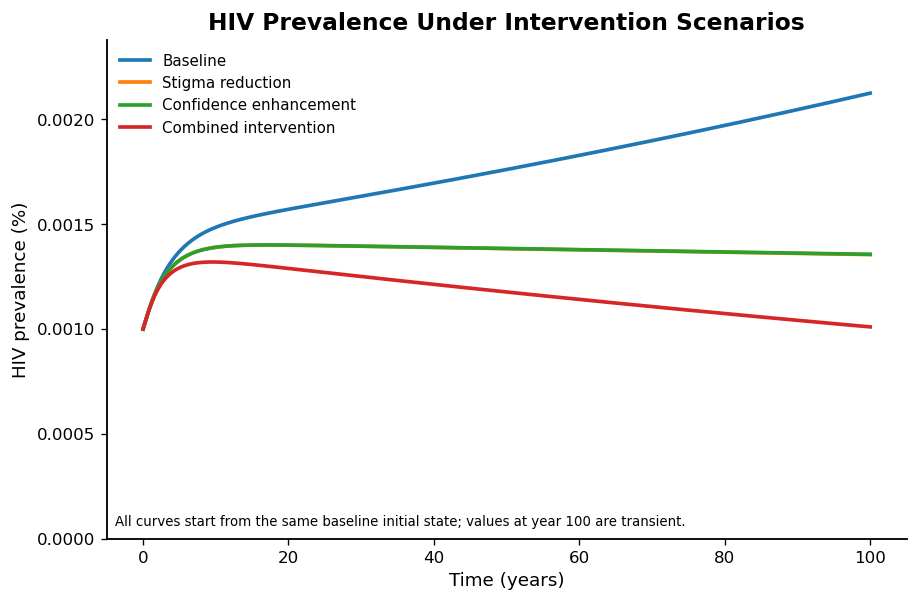

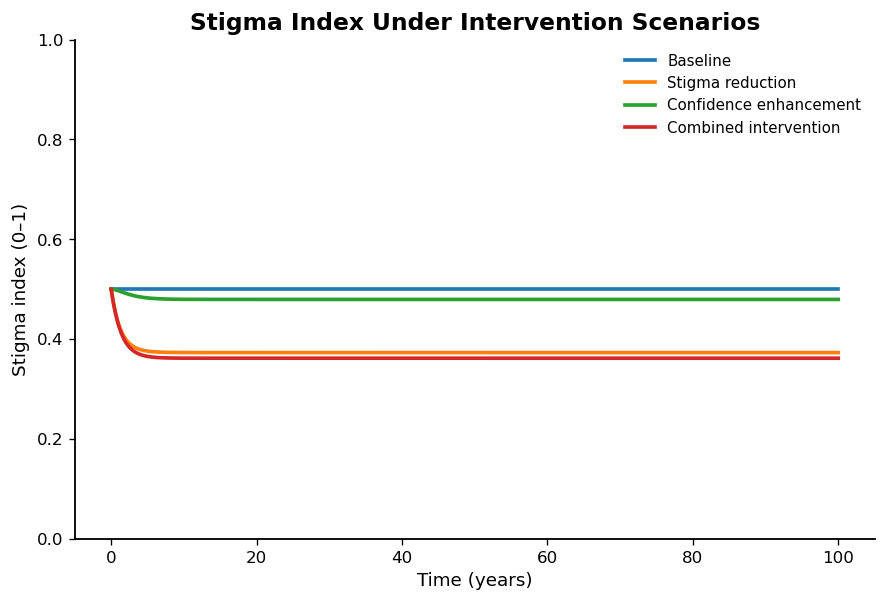

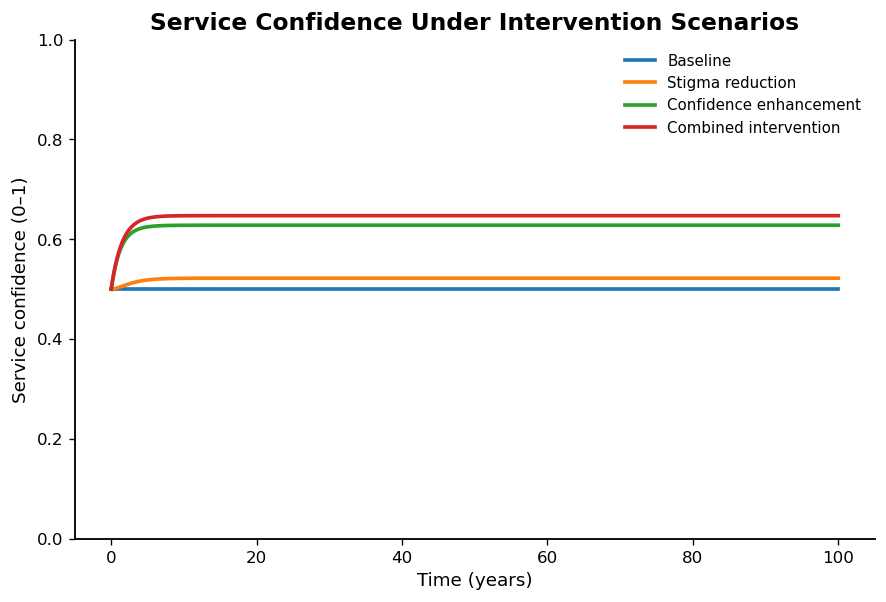

,Metric,Value,Unit
0,Target R0,1.200000e+00,dimensionless
1,Analytical R0,1.200000e+00,dimensionless
2,Next-generation-matrix R0,1.200000e+00,dimensionless
3,Beta,8.666673e-01,1/year
4,Maximum absolute DFE residual,2.970069e-12,state-units/year
5,Population identity max error,3.361689e-12,individuals/year
6,Baseline prevalence at 100 years (transient),2.125107e-03,%
7,Baseline total population at 100 years,9.999874e+04,individuals
8,Baseline DFE PrEP share,8.135593e-01,proportion


,Check,Passed,Details
0,Parameter-domain checks,True,All declared parameter constraints passed.
1,Analytical R0 equals target,True,R0=1.2
2,Analytical R0 matches NGM spectral radius,True,NGM R0=1.2
3,DFE residual below threshold,True,max residual=2.970e-12
4,Population identity verified,True,max error=3.362e-12
5,No materially negative population states,True,minimum=0.000e+00
6,"Social variables remain in [0,1]",True,"range=[0.5,0.5]"
7,Endemic equilibrium candidate found,True,Numerical root search; exploratory.


Figures saved to: /drive/notebooks/03_figures
Tables and parameter files saved to: /drive/notebooks/04_results


In [63]:
SCENARIOS = {
    "Baseline": {"us": 0.00, "uc": 0.00},
    "Stigma reduction": {"us": 0.20, "uc": 0.00},
    "Confidence enhancement": {"us": 0.00, "uc": 0.20},
    "Combined intervention": {"us": 0.20, "uc": 0.20},
}

# Each scenario starts from the same pre-intervention baseline initial state.
# Scenario-specific DFE R0 is reported separately; trajectories are transient.
intervention_results = {}
intervention_records = []
for scenario_name, changes in SCENARIOS.items():
    p = PARAMS.copy()
    p.update(changes)
    scenario_dfe = calculate_dfe(p)
    scenario_r0 = calculate_R0_analytic(p)
    trajectory = simulate(p, Y0, end_time=T_END, n_points=N_EVAL)
    population = trajectory.y[:6].sum(axis=0)
    prevalence = 100.0 * trajectory.y[2:6].sum(axis=0) / population
    intervention_results[scenario_name] = {
        "parameters": p, "dfe": scenario_dfe,
        "solution": trajectory, "prevalence": prevalence,
        "population": population, "R0": scenario_r0,
    }
    intervention_records.append({
        "Scenario": scenario_name,
        "us_stigma_intervention_per_year": changes["us"],
        "uc_confidence_intervention_per_year": changes["uc"],
        "Scenario_DFE_R0": scenario_r0,
        "Scenario_DFE_sigma": scenario_dfe[6],
        "Scenario_DFE_confidence": scenario_dfe[7],
        "Prevalence_at_100y_transient_percent": prevalence[-1],
        "Sigma_at_100y": trajectory.y[6, -1],
        "Confidence_at_100y": trajectory.y[7, -1],
        "Population_at_100y": population[-1],
    })

intervention_table = pd.DataFrame(intervention_records)
intervention_table.to_csv(TABLE_DIR/"intervention_scenario_transient_comparison.csv", index=False)
display(intervention_table)

# Figure 10 — zero-based prevalence axis; values remain in percent.
fig, ax = plt.subplots()
max_prev = 0.0
for name, result in intervention_results.items():
    ax.plot(result["solution"].t, result["prevalence"], label=name)
    max_prev = max(max_prev, float(np.max(result["prevalence"])))
ax.set_ylim(0.0, max_prev*1.12 if max_prev > 0 else 1.0)
ax.set(title="HIV Prevalence Under Intervention Scenarios",
       xlabel="Time (years)", ylabel="HIV prevalence (%)")
ax.legend(loc="best", fontsize=9)
ax.text(0.01, 0.02,
        "All curves start from the same baseline initial state; values at year 100 are transient.",
        transform=ax.transAxes, fontsize=8, va="bottom")
save_figure(fig, "figure_10_intervention_prevalence.png")

# Figure 11 — stigma trajectories.
fig, ax = plt.subplots()
for name, result in intervention_results.items():
    ax.plot(result["solution"].t, result["solution"].y[6], label=name)
ax.set(title="Stigma Index Under Intervention Scenarios",
       xlabel="Time (years)", ylabel="Stigma index (0–1)", ylim=(0, 1))
ax.legend(loc="best", fontsize=9)
save_figure(fig, "figure_11_intervention_stigma.png")

# Figure 12 — service-confidence trajectories.
fig, ax = plt.subplots()
for name, result in intervention_results.items():
    ax.plot(result["solution"].t, result["solution"].y[7], label=name)
ax.set(title="Service Confidence Under Intervention Scenarios",
       xlabel="Time (years)", ylabel="Service confidence (0–1)", ylim=(0, 1))
ax.legend(loc="best", fontsize=9)
save_figure(fig, "figure_12_intervention_confidence.png")

# Export all scenario time series in one consistent structure.
def export_trajectory(solution, filename):
    population = solution.y[:6].sum(axis=0)
    df = pd.DataFrame({
        "time_years": solution.t,
        **{STATE_NAMES[i]: solution.y[i] for i in range(8)},
        "total_population": population,
        "HIV_prevalence_percent": 100.0*solution.y[2:6].sum(axis=0)/population,
    })
    df.to_csv(TABLE_DIR/filename, index=False)

for scenario_name, result in intervention_results.items():
    export_trajectory(result["solution"],
                      "trajectory_"+scenario_name.lower().replace(" ", "_")+".csv")

# Parameter register makes the illustrative / derived / assumed nature explicit.
parameter_notes = {
    "N0": ("individuals", "Scenario scale", "Illustrative population size."),
    "Lambda": ("individuals/year", "Derived", "Set equal to mu*N0 to maintain the chosen baseline population in the absence of excess HIV mortality."),
    "mu": ("1/year", "Assumption", "Background exit rate."),
    "du": ("1/year", "Assumption/proxy", "Excess mortality in undiagnosed infection."),
    "dD": ("1/year", "Assumption/proxy", "Excess mortality after diagnosis without suppression."),
    "dT": ("1/year", "Assumption/proxy", "Excess mortality under sustained suppression."),
    "dL": ("1/year", "Assumption/proxy", "Excess mortality after ART disengagement."),
    "beta": ("1/year", "Scenario-calibrated", "Chosen to obtain target R0=1.20; not independently estimated from incidence data."),
    "epsilon": ("dimensionless", "Assumption/scenario", "PrEP efficacy parameter."),
    "etaD": ("dimensionless", "Assumption", "Relative infectiousness of diagnosed unsuppressed individuals."),
    "etaT": ("dimensionless", "Assumption", "Set to zero as a sustained viral suppression / U=U scenario assumption."),
    "etaL": ("dimensionless", "Assumption", "Relative infectiousness after ART disengagement."),
    "nu0": ("1/year", "Proxy/scenario", "PrEP uptake transition; implied DFE PrEP coverage is high and must not be generalized without calibration."),
    "omega0": ("1/year", "Proxy/scenario", "PrEP discontinuation transition."),
    "tau0": ("1/year", "Derived/proxy", "Diagnosis transition rate; based on an assumed exponential waiting-time interpretation."),
    "kappa0": ("1/year", "Derived/proxy", "ART suppression transition rate; based on an assumed exponential waiting-time interpretation."),
    "delta0": ("1/year", "Proxy/scenario", "ART disengagement transition."),
    "rho0": ("1/year", "Assumption", "Return-to-care transition."),
    "as": ("1/year", "Assumption", "Stigma relaxation/replenishment term in the stated social equation."),
    "bs": ("1/year", "Assumption", "Stigma decay term."),
    "xis": ("1/year", "Assumption", "Stigma-confidence interaction term."),
    "ac": ("1/year", "Assumption", "Baseline confidence-building term."),
    "bc": ("1/year", "Assumption", "Confidence decay term."),
    "xic": ("1/year", "Assumption", "Stigma-confidence interaction term."),
    "zeta": ("dimensionless", "Assumption", "Service-engagement feedback coefficient."),
    "us": ("1/year", "Intervention scenario", "Stigma-reduction intervention intensity."),
    "uc": ("1/year", "Intervention scenario", "Confidence-enhancement intervention intensity."),
    "sigma_ref": ("dimensionless", "Model reference", "Reference stigma index for baseline rate anchoring."),
    "C_ref": ("dimensionless", "Model reference", "Reference confidence index for baseline rate anchoring."),
    "slope": ("dimensionless", "Assumption/scenario", "Common logistic sensitivity slope for stigma and confidence effects."),
}
parameter_register = pd.DataFrame([
    {"Parameter": key, "Value": value,
     "Unit": parameter_notes.get(key, ("", "", ""))[0],
     "Evidence_class": parameter_notes.get(key, ("", "Unclassified", ""))[1],
     "Interpretation": parameter_notes.get(key, ("", "", ""))[2]}
    for key, value in PARAMS.items()
])
parameter_register.to_csv(PARAM_DIR/"parameter_register.csv", index=False)
with open(PARAM_DIR/"model_parameters.json", "w", encoding="utf-8") as handle:
    json.dump({key: (None if value is None else float(value))
               for key, value in PARAMS.items()}, handle, indent=2)

summary = pd.DataFrame([
    ["Target R0", TARGET_R0, "dimensionless"],
    ["Analytical R0", R0_BASE, "dimensionless"],
    ["Next-generation-matrix R0", R0_NGM, "dimensionless"],
    ["Beta", PARAMS["beta"], "1/year"],
    ["Maximum absolute DFE residual", float(np.max(np.abs(DFE_RHS))), "state-units/year"],
    ["Population identity max error", population_identity_error, "individuals/year"],
    ["Baseline prevalence at 100 years (transient)", float(PREV_PCT[-1]), "%"],
    ["Baseline total population at 100 years", float(N[-1]), "individuals"],
    ["Baseline DFE PrEP share", float(DFE[1]/(DFE[0]+DFE[1])), "proportion"],
], columns=["Metric", "Value", "Unit"])
summary.to_csv(TABLE_DIR/"final_numerical_summary.csv", index=False)
display(summary)

# Automated audit checks. Fail loudly if core identities or outputs are inconsistent.
audit_checks = [
    ("Parameter-domain checks", True, "All declared parameter constraints passed."),
    ("Analytical R0 equals target", bool(np.isclose(R0_BASE, TARGET_R0, rtol=1e-10, atol=1e-10)), f"R0={R0_BASE:.12g}"),
    ("Analytical R0 matches NGM spectral radius", bool(np.isclose(R0_BASE, R0_NGM, rtol=1e-9, atol=1e-10)), f"NGM R0={R0_NGM:.12g}"),
    ("DFE residual below threshold", bool(np.max(np.abs(DFE_RHS)) < 1e-8), f"max residual={np.max(np.abs(DFE_RHS)):.3e}"),
    ("Population identity verified", bool(population_identity_error < 1e-8), f"max error={population_identity_error:.3e}"),
    ("No materially negative population states", bool(np.min(Y[:6]) >= -1e-7), f"minimum={np.min(Y[:6]):.3e}"),
    ("Social variables remain in [0,1]", bool(np.min(Y[6:]) >= -1e-8 and np.max(Y[6:]) <= 1+1e-8), f"range=[{np.min(Y[6:]):.6g},{np.max(Y[6:]):.6g}]"),
    ("Endemic equilibrium candidate found", bool(any(row["Type"] == "Endemic" for row in eq_rows)), "Numerical root search; exploratory."),
]
audit_table = pd.DataFrame(audit_checks, columns=["Check", "Passed", "Details"])
audit_table.to_csv(TABLE_DIR/"automated_audit_checks.csv", index=False)
display(audit_table)
if not audit_table["Passed"].all():
    raise RuntimeError("At least one automated audit check failed. Do not use these outputs.")

print(f"Figures saved to: {FIGURE_DIR}")
print(f"Tables and parameter files saved to: {RESULT_DIR}")

In [ ]:
# Save this notebook (Cmd+S / Ctrl+S) before running this cell if you want the
# ZIP archive to contain the newest executed notebook outputs.
ZIP_PATH = PROJECT_ROOT.parent / "HIV_MSM_Research_Package.zip"

# Rebuild the manifest from the exact current files; never reuse a prior manifest.
import hashlib
manifest_path = DOC_DIR / "MANIFEST.csv"
manifest_rows = []
for file_path in sorted(PROJECT_ROOT.rglob("*")):
    if file_path.is_file() and file_path != manifest_path:
        digest = hashlib.sha256(file_path.read_bytes()).hexdigest()
        manifest_rows.append({
            "path": str(file_path.relative_to(PROJECT_ROOT)),
            "size_bytes": file_path.stat().st_size,
            "sha256": digest,
        })
pd.DataFrame(manifest_rows).to_csv(manifest_path, index=False)

# The ZIP includes the complete project folder and all current generated outputs.
# It is written outside PROJECT_ROOT so it cannot include itself.
with zipfile.ZipFile(ZIP_PATH, mode="w", compression=zipfile.ZIP_DEFLATED,
                     compresslevel=6) as archive:
    for path in sorted(PROJECT_ROOT.rglob("*")):
        if not path.is_file():
            continue
        if any(part in {"__pycache__", ".ipynb_checkpoints"} for part in path.parts):
            continue
        archive.write(path, arcname=path.relative_to(PROJECT_ROOT.parent))

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    bad_member = archive.testzip()
    if bad_member is not None:
        raise RuntimeError(f"ZIP integrity test failed at {bad_member}")
    archive_members = archive.namelist()

print(f"ZIP package created: {ZIP_PATH}")
print(f"Files included: {len(archive_members)}")
print("ZIP integrity test: passed")